In [1]:
# Import libraries

#--- Standard Libraries: general utilities ---
import difflib # Compare text and find close matches
import json # Read and write JSON data
import operator # Function versions of operators, such as add for state reducers
import os # Access environment variables
from datetime import datetime # Create and format timestamps
from pathlib import Path # Work with file paths

# --- Standard library: type hints ---
from typing import Annotated, Literal, TypedDict # Define state schemas and restrict allowed values

# --- Configuration ---
from dotenv import load_dotenv # Load API keys and settings from .env

# --- Data handling and HTTP requests ---
import pandas as pd # Load and manipulate tabular data
import requests # Call external HTTP APIs

# --- LLM providers and clients ---
from langchain_openai import ChatOpenAI # LangChain chat model for OpenAI-compatible APIs
from openrouter import OpenRouter # OpenRouter SDK client

# --- LangChain: agents and tools
from langchain.agents import create_agent # Build an agent that can call tools
from langchain.agents.middleware import HumanInTheLoopMiddleware # Pause tool calls for human review
from langchain_core.tools import tool # Turn Python functions into agent tools

# --- LangGraph: workflow orchestration ---
from langgraph.checkpoint.memory import InMemorySaver # Save graph state in memory between steps
from langgraph.graph import END, START, StateGraph # Define graph state, nodes, edges, and entry/exit points
from langgraph.types import Command, RetryPolicy, Send # Resume or redirect runs, retry failed nodes, and fan out work

# --- Langfuse: tracing and observability ---
from langfuse import get_client # Access the configured Langfuse client
from langfuse.langchain import CallbackHandler # Trace LangChain and LangGraph runs in Langfuse

# --- Local modules ---
from week2day1_payout import Benefit, Line, Payout, work_out_payout # Payout data models and calculation logic


### Connect to OpenRouter and Langfuse

In [2]:
load_dotenv(override=True)

openrouter_api_key = os.getenv('OPENROUTER_API_KEY')
OPENROUTER_BASE_URL = 'https://openrouter.ai/api/v1'

if openrouter_api_key:
    print("OpenRouter API Key found and starts with:", openrouter_api_key[:5])
else:
    print("OpenRouter API Key not found") 

langfuse = get_client()
langfuse_handler = CallbackHandler()

if langfuse.auth_check():
    print("Connected to Langfuse")
else:
    print("Failed to connect to Langfuse")


OpenRouter API Key found and starts with: sk-or
Connected to Langfuse


## Part 1: A judge with a reference answer

In [3]:
DATA = Path("../../../data")

def load(name): # Load a JSON seed file by name
    """ Read one of the JSON seed files"""
    return json.loads((DATA / name).read_text(encoding='utf-8'))

def get_sample_data(tiny=False, held_out=False): # Get sample data from the JSON seed files
    """ Return a list of claims, and the handlers' decisions on them keyed by claim id. """
    claims = load('evals/held_out_claims.json' if held_out else 'claims.json')
    decisions = load('evals/held_out_decisions.json' if held_out else 'evals/decisions.json')
    if tiny:
        chosen = {decision['claim_id'] for decision in decisions if decision['tiny']}
        claims = [claim for claim in claims if claim['claim_id'] in chosen]
        decisions = [decision for decision in decisions if decision['tiny']]
    labels = {decision['claim_id']: decision for decision in decisions}
    return claims, labels

In [4]:
TINY = False

evaluation_claims, evaluation_labels = get_sample_data(tiny=TINY) # Load evaluation claims and labels
held_out_claims, held_out_labels= get_sample_data(tiny=TINY, held_out=True) # Load held-out claims and labels

claims = {claim['claim_id']: claim for claim in evaluation_claims + held_out_claims} # Combine evaluation and held-out claims into a dictionary keyed by claim_id
labels = evaluation_labels | held_out_labels # Combine evaluation and held-out labels into a single dictionary
policies = {policy['policy_id']: policy for policy in load('policies.json')} # Load policies into a dictionary keyed by policy_id
policy_wording = (DATA / 'policy_wording.md').read_text(encoding='utf-8') # Read the policy wording from the markdown file

SETS = {'evaluation': list(evaluation_labels), 'held-out': list(held_out_labels)} # Defines the sets of claim IDs for evaluation and held-out data
print(f"{len(SETS['evaluation'])} evaluation claims and {len(SETS['held-out'])} held-out claims") # Print the number of evaluation and held-out claims

25 evaluation claims and 25 held-out claims


### The handler's reasons

In [5]:
# Load the whole queue, in case TINY is True
queue_claims, queue_labels = get_sample_data() # Load the full queue of claims and labels
handler = queue_labels['CLM-1001'] # Get the handler for the claim with ID 'CLM-1001'

print(f"Decision: {handler['decision']} ${handler['payout']:,.2f}") # Print the decision and payout for the handler of the claim with ID 'CLM-1001'
print(f"Reason: {handler['reason']}") # Print the reason for the decision of the handler of the claim with ID 'CLM-1001'
print(f"Reference: {handler['reference']}") # Print the reference for the decision of the handler of the claim with ID 'CLM-1001'

Decision: approve $420.00
Reason: The carrier canceled the flight for a crew problem and the delay was 19 hours, well past the 6 hour waiting period on Premium. The hotel, meals and taxis are reasonable and all have receipts. The total is inside the $800 maximum.
Reference: Policy wording, section 3


### A reference-guided judge

In [6]:
JEV = 'typesafe/jev-1.13' # Define the JEV version to be used

# Jev numbers the grade by their position in the list, so F is 0 and A is 3
RUBRIC = {
    'F': "different ground from the handler's reason, or it contradicts the handler's reason", 
    'C': "partly the same as the handler's reason: one of the handler's grounds or the section is missing, or it adds a ground the handler did not give",
    'B': "the same grounds and the same section of the policy wording as the handler's reason",
    'A': "the same grounds and section as the handler's reason, and clearly better expressed: clearer for the customer, with the section and the figures, shorter, and no jargon",
}
GRADES = list(RUBRIC)

JUDGE_QUESTIONS = {
    'grade': {
        'type': 'score',
        'instructions': 'An expert claims handler decided a travel insurance claim and gave `handler.reason`, resting on `handler.reference`. Grade how well `agent.rationale` explains the same decision.',
        'criteria': [f"{letter}: {text}" for letter, text in RUBRIC.items()],
    },
    'same_grounds': {'type': 'noul', 'instructions': '`agent.rationale` gives the same main grounds for the decision as `handler.reason`'},
    'same_section': {'type': 'noul', 'instructions': '`agent.rationale` refers to the same section of the policy wording as `handler.reference`'},
}

openrouter_decisions = OpenRouter(api_key=openrouter_api_key, timeout_ms=60_000)

def judge(rationale, decision, expected):
    """ Ask Jev to grade a rationale against the handler's reason."""
    state = {
        'handler':
            {
                'decision': expected['decision'], 
                'reason': expected['reason'],
                'reference': expected['reference']
            },
        'agent':
        {
            'decision': decision,
            'rationale': rationale,
        }
    }
    response = openrouter_decisions.alpha.decisions.create(model=JEV,
                                                          state=state,
                                                          questions=JUDGE_QUESTIONS)
    answers = response.answers
    probabilities = answers['grade'].probabilities
    most_likely = max(probabilities,
                      key=probabilities.get)
    return {
        'grade': answers['grade'].score,
        'letter': GRADES[int(most_likely)],
        'same_grounds': answers['same_grounds'].noul,
        'same_section': answers['same_section'].noul,
        'judge_cost': response.usage.cost
    }


### Checking the judge

In [7]:
other_claim = queue_labels['CLM-1003']
tests ={
    "The handler's reason": f"{handler['reason']} ({handler['reference']})",
    "a different claim's reason": other_claim['reason'],
    "Vague": "The flight was cancelled and the customer stayed in a hotel, so we approve the claim.",
    "Clearer than the handler": "Approved under section 3: the crew problem delayed your flight by 19 hours, past the 6 hour waiting period on Premium. We pay the $420 for your hotel, meals and taxis in full, since every item has a receipt and the total is under the $800 limit.",
}

rows = []
for name, rationale in tests.items():
    rows.append({'rationale': name, 
                **judge(rationale,  
                        'approve', 
                        handler)})

pd.DataFrame(rows).round(2)

,rationale,grade,letter,same_grounds,same_section,judge_cost
0,The handler's reason,2.03,B,0.99,0.99,0.0
1,a different claim's reason,0.00,F,0.02,0.07,0.0
2,Vague,0.91,C,0.29,0.20,0.0
3,Clearer than the handler,2.86,A,0.99,0.98,0.0


## Part 2: Version 1 and its scores

### The configuration

In [8]:
INSTRUCTIONS = """ You are a claims handler at UnderCover Travel Insurance. Decide the claim you are given, using the policy
wording below and the customer's policy record.


Choose one decision:
- approve: the wording covers the claim and the required documents are attached. Work out the payout using section 10.
- decline: the wording does not cover the claim.
- refer: a colleague needs to look at it, because a required document is missing, or the story and the documents disagree, or the wording does not settle the question.

Use your tools to record your decision.
Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
"""

versions = [
    {
        'version': 1,
        'instructions': INSTRUCTIONS,
        'model': 'openai/gpt-6-luna',
        'reasoning_effort': 'low'
    }]
current = 1

### The claim agent


In [10]:
recorded = {}

@tool(parse_docstring=True) #  This tool will be used to record decisions made on claims.
def record_decision(claim_id: str, rationale: str, decision: Literal['approve', 'decline', 'refer'], payout: float) -> str:
    """ Record the decision on a claim in the claims system.
    
    Args: 
        claim_id: The claim's id
        rationale: 2-3 sentences explaining the decision along with the relevant section of the policy 
        decision: The decision on the claim
        payout: The amount to pay in US dollars, or 0 for a decline or a referral
    """

    if claim_id in recorded:
        return f"A decision is already recorded for claim{claim_id}, and decisions are final"
    if decision == 'approve' and payout <= 0:
        return "An approval needs a payout above zero"
    recorded[claim_id] = {'decision': decision,
                          'payout': payout,
                          'rationale': rationale}
    return f"Recorded {decision} on {claim_id}"

@tool(parse_docstring=True) # This tool will be used to retrieve recorded decisions.
def calculate_payment(policy_id: str, benefit: Benefit, lines: list[Line], paid_by_others: float = 0.0) -> float:
    """ Work out the payout on an approved claim with UnderCover's payout rules. 
    
    Args:
        policy_id: the customer's policy id
        benefit: the benefit the claim is paid under
        lines: The covered items and expenses, one for each line of the claim, with any excluded ones left out. A pair or a set counts as one item
        paid_by_others: Anything a carrier, hotel or other party has paid or refunded for the same loss

    Returns: 
        The calculation, the payout and whether it needs sign-off
    """

    return work_out_payout(policies[policy_id], benefit, lines, paid_by_others)


In [11]:
def make_user_prompt(claim): # Generate a user prompt for a given claim
    """ The customer's policy record and the claim as JSON."""
    policy = policies[claim['policy_id']]
    return f"""# Policy record
    
    {json.dumps(policy, indent=2)}
    
    # Claim 

    {json.dumps(claim, indent=2)}
    """

    def make_agent(claim): # Generate an agent prompt for a given claim
        """ Build the claim agent for one version of the configuration. """
        model = ChatOpenAI(
            model=config['model'],
            base_url=OPENROUTER_BASE_URL,
            api_key=openrouter_api_key,
            reasoning_effort=config['reasoning_effort'],
            timeout=120, 
            max_retries=5
        )
        return create_agent(
            model=model,
            tools=[record_decision, 
                   calculate_payout],
            system_prompt=f"{config['instructions']}\n{policy_wording}\n"
        )

### The dispatcher

In [15]:
class Dispatch(TypedDict): # Dispatcher state for one run
    """ What the dispatcher keeps for one run."""

    config: dict
    claims: list[str]
    results: Annotated[list, operator.add]

def fan_out(state: Dispatch): # Fan out claims for processing
    """ Send each claim to a claim agent, with the configuration to use. """
    return [Send('work_claim', {'claim_id': claim_id, 'config': state['config']}) for claim_id in state['claims']]

def work_claim(task): # Process a single claim
    """ Run a claim agent on one claim and return its result. """
    claim_id = task['claim_id']
    agent = make_agent(task['config'])
    started = datetime.now()
    result = agent.invoke(
        {
            'messages': 
            [
                {'role': 'user',
                'content': make_user_prompt(claims[claim_id])
                }
            ]
        }
    )
    answer = recorded.get(claim_id,
                            {'decision': 'refer',
                            'payout': 0.0,
                            'rationale': 'Nothing recorded'})
    cost = sum(message.response_metadata['token_usage']['cost'] for message in result['messages'] if message.type == 'ai')
    return {'results': [{'claim_id': claim_id, **answer, 'cost': cost, 'started': started, 'finished': datetime.now()}]}

builder = StateGraph(Dispatch) # Build the state graph for dispatching claims 
builder.add_node('work_claim', work_claim, retry_policy=RetryPolicy(max_attempts=3))
builder.add_conditional_edges(START, fan_out, ['work_claim'])
builder.add_edge('work_claim', END)
dispatcher = builder.compile()

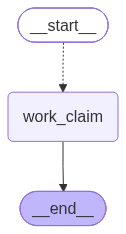

In [16]:
dispatcher

### Scoring a run

In [18]:
WRONGFUL_DECLINE = 1500
NEEDLESS_REFERRAL = 50

def is_right(answer, expected): # Check if the answer is correct
    """ True when the decision matches the handler's and the payout is within a dollar. """
    return answer['decision'] == expected['decision'] and abs(answer['payout'] - expected['payout']) <= 1

def mistake_cost(answer, expected): # Calculate the cost of a mistake
    """ What the agent's answer costs UnderCover, against the handler's decision. """
    if answer['decision'] == expected['decision']:
        return abs(answer['payout'] - expected['payout']) if answer['decision'] == 'approve' else 0
    if answer['decision'] =='decline':
        return WRONGFUL_DECLINE
    if answer['decision'] == 'approve':
        return answer['payout']
    return NEEDLESS_REFERRAL